# Advanced trend analysis (undergraduate → graduate level)
Runs on `all_data.csv` (4 places × 528 months; 10 variables from MERRA-2, GLDAS, GPM IMERG and MERRA-2 aerosols).

| § | Method | Level | Where it comes from |
|---|---|---|---|
| 1 | Autocorrelation-aware trend tests: Hamed–Rao modified Mann-Kendall, GLS with AR(1) errors, moving-block bootstrap | Graduate | Extends regression (MAML §6.1, Stat 2 ch. 7–8) and the bootstrap (Multivariate notes); time-series methods beyond your notes |
| 2 | Sen's slope with rank-based confidence interval | Advanced UG | Nonparametric statistics (beyond your notes) |
| 3 | Change points: Pettitt test + piecewise (broken-stick) regression chosen by BIC / likelihood ratio | Advanced UG → Grad | Stat 2 §11 (likelihood ratio, Wilks), §17.3 (BIC) |
| 4 | Bayesian linear regression (Jeffreys prior): posterior, credible interval, P(direction), Bayes factor | Advanced UG | Stat 2 ch. 15–17 |
| 5 | Quantile regression: are the extremes changing faster than the average? | Graduate | Beyond your notes (Koenker) |
| 6 | Gaussian process regression: smooth non-linear trend with uncertainty | Graduate | Multivariate notes §7.2 |
| 7 | EOF / PCA: the coupled "Earth-system mode" of each place | Advanced UG → Grad | Multivariate notes §3.5 |
| 8 | Lagged cross-correlation: rain → soil moisture memory | Advanced UG | Prob 2 ch. 3 (covariance, correlation) |
| 9 | Do two NASA sources agree? Bland–Altman + trend-of-the-difference test | Advanced UG | Stat 1 ch. 6–9 |
| 10 | Robust verdict: what survives every check | — | Combines all of the above + Stat 2 §17.4 (FDR) |

Install once: `pip install statsmodels scikit-learn pymannkendall scipy matplotlib`

In [1]:
import numpy as np
import pandas as pd
import pymannkendall as mk
import statsmodels.api as sm
from scipy import stats
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

VARIABLES = {   # column: (name, units, source)
    "T2M":           ("Air temperature",      "°C",     "MERRA-2"),
    "PRECTOTCORR":   ("Rainfall (model)",     "mm/day", "MERRA-2"),
    "gpm_rain":      ("Rainfall (satellite)", "mm/day", "GPM IMERG"),
    "RH2M":          ("Humidity",             "%",      "MERRA-2"),
    "GWETTOP":       ("Topsoil wetness",      "0-1",    "MERRA-2"),
    "soil_moisture": ("Soil moisture",        "kg/m²",  "GLDAS"),
    "evaporation":   ("Evaporation",          "mm/day", "GLDAS"),
    "runoff":        ("Runoff",               "mm/day", "GLDAS"),
    "aerosol":       ("Haze (aerosol)",       "AOD",    "MERRA-2 aer."),
    "dust":          ("Dust",                 "AOD",    "MERRA-2 aer."),
}
PLACES = ["amazon", "london", "sahara", "sahel"]

df = pd.read_csv("all_data.csv", parse_dates=["date"])
df["year"] = df["date"].dt.year

def yearly(place, col):
    """Yearly means (complete years only): removes the seasonal cycle."""
    g = df[df.place == place][["year", col]].dropna()
    y = g.groupby("year")[col].mean()
    y = y[g.groupby("year").size() == 12]
    return y.index.values.astype(float), y.values

def monthly_anomalies(place, col):
    """Monthly values minus each calendar month's average (another way to remove seasons)."""
    s = df[df.place == place].set_index("date")[col].dropna()
    return s - s.groupby(s.index.month).transform("mean")

def series():
    for place in PLACES:
        for col, (name, units, source) in VARIABLES.items():
            t, y = yearly(place, col)
            yield place, col, name, units, source, t, y

# Chart style (colour-blind-safe blue/orange)
BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb6834", "#0b0b0b", "#c9c8c2"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ebeae6", "axes.axisbelow": True, "figure.dpi": 110,
                     "axes.titlelocation": "left", "axes.titlesize": 10.5, "legend.frameon": False})
print(f"{df.place.nunique()} places, {len(VARIABLES)} variables, {len(df)} monthly rows")

4 places, 10 variables, 2112 monthly rows


## 1. Autocorrelation-aware trend tests (graduate level)
Ordinary t-tests and Mann-Kendall assume each year is independent. Climate data often has **memory** (a dry year tends to follow a dry year), which makes trends look *more* significant than they are. Three standard fixes:

- **Hamed–Rao modified Mann-Kendall:** inflates the test's variance using the autocorrelation of the ranks.
- **Generalised least squares with AR(1) errors:** regression that models residuals as $e_t = \rho e_{t-1} + u_t$ (iterated Cochrane–Orcutt).
- **Moving-block bootstrap:** resamples *blocks* of consecutive years (Efron's bootstrap from your Multivariate notes, adapted so the memory is kept).

In [2]:
rng = np.random.default_rng(42)

def gls_ar1(t, y):
    X = sm.add_constant(t - t.mean())
    model = sm.GLSAR(y, X, rho=1)
    res = model.iterative_fit(maxiter=20)
    return res.params[1], res.bse[1], res.pvalues[1], float(model.rho[0])

def block_bootstrap_ci(t, y, B=2000, block=4):
    n = len(y)
    starts = rng.integers(0, n - block + 1, size=(B, int(np.ceil(n / block))))
    idx = (starts[:, :, None] + np.arange(block)).reshape(B, -1)[:, :n]
    tb, yb = t[idx], y[idx]
    tc = tb - tb.mean(axis=1, keepdims=True)
    slopes = (tc * (yb - yb.mean(axis=1, keepdims=True))).sum(1) / (tc ** 2).sum(1)
    return np.percentile(slopes, [2.5, 97.5])

rows = []
for place, col, name, units, source, t, y in series():
    ols = stats.linregress(t - t.mean(), y)
    resid = y - (ols.intercept + ols.slope * (t - t.mean()))
    hr = mk.hamed_rao_modification_test(y)
    b, se, p_gls, rho = gls_ar1(t, y)
    lo, hi = block_bootstrap_ci(t, y)
    rows.append({"Place": place.title(), "Variable": name, "Units": units,
                 "OLS per decade": ols.slope * 10, "OLS p": ols.pvalue,
                 "Lag-1 autocorr": np.corrcoef(resid[:-1], resid[1:])[0, 1],
                 "Original MK p": mk.original_test(y).p, "Hamed–Rao MK p": hr.p,
                 "GLS-AR(1) per decade": b * 10, "GLS-AR(1) p": p_gls, "AR(1) rho": rho,
                 "Block-bootstrap CI low": lo * 10, "Block-bootstrap CI high": hi * 10})
sec1 = pd.DataFrame(rows)
print("Significant (p<0.05):  OLS", (sec1["OLS p"] < .05).sum(),
      "| original MK", (sec1["Original MK p"] < .05).sum(),
      "| Hamed–Rao MK", (sec1["Hamed–Rao MK p"] < .05).sum(),
      "| GLS-AR(1)", (sec1["GLS-AR(1) p"] < .05).sum(),
      "| block bootstrap", ((sec1["Block-bootstrap CI low"] > 0) | (sec1["Block-bootstrap CI high"] < 0)).sum(),
      "of", len(sec1))
sec1.round(4)

Significant (p<0.05):  OLS 27 | original MK 21 | Hamed–Rao MK 20 | GLS-AR(1) 22 | block bootstrap 17 of 40


,Place,Variable,Units,OLS per decade,OLS p,Lag-1 autocorr,Original MK p,Hamed–Rao MK p,GLS-AR(1) per decade,GLS-AR(1) p,AR(1) rho,Block-bootstrap CI low,Block-bootstrap CI high
0,Amazon,Air temperature,°C,0.3258,0.0000,0.2897,0.0001,0.0000,0.3586,0.0004,0.2859,0.1556,0.4757
1,Amazon,Rainfall (model),mm/day,-0.3949,0.0010,0.3950,0.0019,0.0140,-0.4826,0.0081,0.3961,-0.9138,-0.1359
2,Amazon,Rainfall (satellite),mm/day,-0.4619,0.0838,0.0512,0.1290,0.1290,-0.3870,0.1877,0.0402,-0.7869,0.3679
3,Amazon,Humidity,%,-0.8313,0.0091,0.3448,0.0363,0.0132,-0.9786,0.0372,0.3458,-1.7876,0.0515
4,Amazon,Topsoil wetness,0-1,-0.0154,0.0278,0.3647,0.0420,0.0046,-0.0189,0.0761,0.3708,-0.0422,0.0013
5,Amazon,Soil moisture,kg/m²,-0.6503,0.0394,0.4039,0.1071,0.1071,-0.5455,0.2188,0.3380,-1.3131,0.4492
6,Amazon,Evaporation,mm/day,0.0773,0.2362,0.7240,0.3383,0.5398,-0.0748,0.5445,0.6600,-0.2886,0.4156
7,Amazon,Runoff,mm/day,0.0282,0.6392,0.2450,0.7261,0.7261,0.0390,0.6350,0.2359,-0.1594,0.2988
8,Amazon,Haze (aerosol),AOD,0.0261,0.0150,-0.0223,0.0585,0.0585,0.0215,0.0426,-0.0409,-0.0099,0.0348
9,Amazon,Dust,AOD,0.0027,0.0013,0.2399,0.0161,0.0198,0.0024,0.0252,0.2365,-0.0016,0.0064


## 2. Sen's slope with a rank-based confidence interval
The median of all pairwise slopes $(y_j - y_i)/(t_j - t_i)$. Unlike least squares, one freak year (e.g. Sahel 2024) can't drag it around. The confidence interval comes from the Mann-Kendall variance $\text{Var}(S) = n(n-1)(2n+5)/18$.

In [3]:
def sen_slope_ci(t, y, alpha=0.05):
    i, j = np.triu_indices(len(t), 1)
    slopes = np.sort((y[j] - y[i]) / (t[j] - t[i]))
    n, N = len(y), len(slopes)
    C = stats.norm.ppf(1 - alpha / 2) * np.sqrt(n * (n - 1) * (2 * n + 5) / 18)
    m1, m2 = int(np.floor((N - C) / 2)), int(np.ceil((N + C) / 2))
    return np.median(slopes), slopes[max(m1 - 1, 0)], slopes[min(m2, N - 1)]

rows = []
for place, col, name, units, source, t, y in series():
    s, lo, hi = sen_slope_ci(t, y)
    ols = stats.linregress(t, y).slope
    rows.append({"Place": place.title(), "Variable": name, "Units": units,
                 "Sen per decade": s * 10, "CI low": lo * 10, "CI high": hi * 10,
                 "OLS per decade": ols * 10,
                 "CI excludes 0": (lo > 0) or (hi < 0)})
sec2 = pd.DataFrame(rows)
sec2.round(4)

,Place,Variable,Units,Sen per decade,CI low,CI high,OLS per decade,CI excludes 0
0,Amazon,Air temperature,°C,0.2900,0.1604,0.4220,0.3258,True
1,Amazon,Rainfall (model),mm/day,-0.3818,-0.6027,-0.1510,-0.3949,True
2,Amazon,Rainfall (satellite),mm/day,-0.4875,-1.0410,0.1352,-0.4619,False
3,Amazon,Humidity,%,-0.6371,-1.2615,-0.0532,-0.8313,True
4,Amazon,Topsoil wetness,0-1,-0.0152,-0.0300,-0.0005,-0.0154,True
5,Amazon,Soil moisture,kg/m²,-0.4743,-1.2798,0.1013,-0.6503,False
6,Amazon,Evaporation,mm/day,0.0832,-0.0835,0.2472,0.0773,False
7,Amazon,Runoff,mm/day,0.0226,-0.0935,0.1510,0.0282,False
8,Amazon,Haze (aerosol),AOD,0.0249,-0.0002,0.0490,0.0261,False
9,Amazon,Dust,AOD,0.0026,0.0007,0.0043,0.0027,True


## 3. Change points: when did things change?
- **Pettitt test** (nonparametric): finds the year where the series most likely shifts level. $U_k = \sum_{i\le k}\sum_{j>k}\text{sgn}(y_j-y_i)$, $K=\max|U_k|$, $p \approx 2\exp\!\left(-6K^2/(n^3+n^2)\right)$.
- **Broken-stick regression:** a straight line that is allowed to bend once. Compared with a single straight line using **BIC** (Stat 2 §17.3) and the **likelihood ratio test** (Stat 2 §11.2).

In [4]:
def pettitt(t, y):
    n = len(y)
    S = np.sign(y[None, :] - y[:, None])                     # S[i, j] = sgn(y_j - y_i)
    U = np.array([S[:k, k:].sum() for k in range(1, n)])
    k = int(np.argmax(np.abs(U)))
    K = np.abs(U[k])
    p = min(1.0, 2 * np.exp(-6 * K ** 2 / (n ** 3 + n ** 2)))
    return int(t[k + 1]), p                                  # first year of the new regime

def loglik(resid):
    n = len(resid)
    return -n / 2 * (np.log(2 * np.pi * resid @ resid / n) + 1)

def broken_stick(t, y, min_seg=6):
    X1 = np.column_stack([np.ones_like(t), t - t.mean()])
    r1 = y - X1 @ np.linalg.lstsq(X1, y, rcond=None)[0]
    best = None
    for b in t[min_seg:-min_seg]:
        X2 = np.column_stack([X1, np.maximum(t - b, 0)])
        coef = np.linalg.lstsq(X2, y, rcond=None)[0]
        r2 = y - X2 @ coef
        if best is None or r2 @ r2 < best[1] @ best[1]:
            best = (b, r2, coef)
    b, r2, coef = best
    n = len(y)
    bic1 = 3 * np.log(n) - 2 * loglik(r1)
    bic2 = 5 * np.log(n) - 2 * loglik(r2)                   # + slope change + break year
    lr = 2 * (loglik(r2) - loglik(r1))
    return int(b), coef, bic1, bic2, stats.chi2.sf(lr, 2)

rows = []
for place, col, name, units, source, t, y in series():
    cp_year, cp_p = pettitt(t, y)
    b, coef, bic1, bic2, lr_p = broken_stick(t, y)
    rows.append({"Place": place.title(), "Variable": name,
                 "Pettitt change year": cp_year, "Pettitt p": cp_p,
                 "Best bend year": b,
                 "Slope before (per decade)": coef[1] * 10, "Slope after (per decade)": (coef[1] + coef[2]) * 10,
                 "BIC straight": bic1, "BIC bent": bic2,
                 "Better model (BIC)": "bent" if bic2 < bic1 else "straight", "LRT p": lr_p})
sec3 = pd.DataFrame(rows)
print("Significant change points (Pettitt p<0.05):", (sec3["Pettitt p"] < .05).sum(),
      "| BIC prefers a bend:", (sec3["Better model (BIC)"] == "bent").sum(), "of", len(sec3))
sec3.round(4)

Significant change points (Pettitt p<0.05): 16 | BIC prefers a bend: 12 of 40


,Place,Variable,Pettitt change year,Pettitt p,Best bend year,Slope before (per decade),Slope after (per decade),BIC straight,BIC bent,Better model (BIC),LRT p
0,Amazon,Air temperature,2005,0.0011,1987,-0.3349,0.3670,83.3333,89.9653,straight,0.6261
1,Amazon,Rainfall (model),2003,0.0021,1993,0.9985,-0.7347,129.1432,127.3502,bent,0.0093
2,Amazon,Rainfall (satellite),2022,0.4838,2018,-0.0310,-2.6122,74.4182,77.4675,straight,0.1837
3,Amazon,Humidity,2005,0.0905,1987,2.1128,-1.0149,216.8369,223.5111,straight,0.6395
4,Amazon,Topsoil wetness,2003,0.0805,1987,0.0826,-0.0215,-118.0428,-112.5004,straight,0.3631
5,Amazon,Soil moisture,2009,0.2116,2018,-0.4398,-1.7009,82.0665,87.9409,straight,0.7545
6,Amazon,Evaporation,2009,0.0666,2013,0.5183,-0.4839,4.8626,-16.0929,bent,0.0000
7,Amazon,Runoff,2011,0.4004,2013,0.2530,-0.2579,1.3930,2.2910,straight,0.0627
8,Amazon,Haze (aerosol),2015,0.2950,2018,0.0081,0.1158,-88.0929,-85.6320,straight,0.1369
9,Amazon,Dust,2017,0.0039,2013,-0.0002,0.0064,-218.6455,-218.4165,straight,0.0449


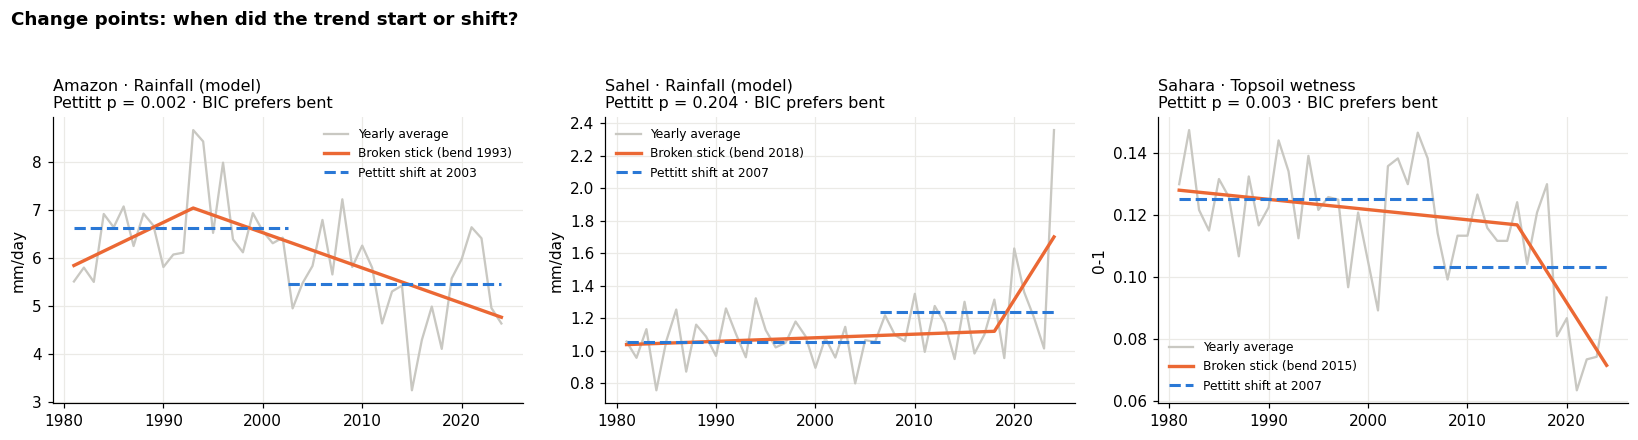

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (place, col) in zip(axes, [("amazon", "PRECTOTCORR"), ("sahel", "PRECTOTCORR"), ("sahara", "GWETTOP")]):
    t, y = yearly(place, col)
    name, units, _ = VARIABLES[col]
    cp_year, cp_p = pettitt(t, y)
    b, coef, bic1, bic2, lr_p = broken_stick(t, y)
    X2 = np.column_stack([np.ones_like(t), t - t.mean(), np.maximum(t - b, 0)])
    ax.plot(t, y, color=GREY, lw=1.5, label="Yearly average")
    ax.plot(t, X2 @ coef, color=ORANGE, lw=2.2, label=f"Broken stick (bend {b})")
    before, after = y[t < cp_year].mean(), y[t >= cp_year].mean()
    ax.hlines(before, t.min(), cp_year - 0.5, color=BLUE, lw=2, ls="--")
    ax.hlines(after, cp_year - 0.5, t.max(), color=BLUE, lw=2, ls="--", label=f"Pettitt shift at {cp_year}")
    ax.set_title(f"{place.title()} · {name}\nPettitt p = {cp_p:.3f} · BIC prefers {'bent' if bic2 < bic1 else 'straight'}")
    ax.set_ylabel(units)
    ax.legend(fontsize=8, loc="best")
fig.suptitle("Change points: when did the trend start or shift?", x=0.01, ha="left", fontweight="bold", y=1.04)
fig.tight_layout()
plt.show()

## 4. Bayesian linear regression (Stat 2 ch. 15–17)
With the Jeffreys prior $p(\beta,\sigma^2)\propto 1/\sigma^2$, the posterior for the slope is a Student-t centred on $\hat\beta$ with scale $\text{SE}(\hat\beta)$ and $n-2$ degrees of freedom. That gives a **95% credible interval** ("95% probability the true slope is in here"), **P(trend in the observed direction)**, and a **Bayes factor** (trend vs no trend) via the Schwarz/BIC approximation (Stat 2 §17.3), read on the Kass–Raftery scale (Stat 2 Table 17.2).

In [6]:
def kass_raftery(bf):
    return ("favours no trend" if bf < 1 else "barely worth mentioning" if bf < 3 else
            "positive" if bf < 20 else "strong" if bf < 150 else "very strong")

rows = []
for place, col, name, units, source, t, y in series():
    n = len(y)
    ols = stats.linregress(t - t.mean(), y)
    post = stats.t(df=n - 2, loc=ols.slope * 10, scale=ols.stderr * 10)
    p_dir = post.cdf(0) if ols.slope < 0 else post.sf(0)
    r1 = y - (ols.intercept + ols.slope * (t - t.mean()))
    r0 = y - y.mean()
    bf = np.exp(((2 * np.log(n) - 2 * loglik(r0)) - (3 * np.log(n) - 2 * loglik(r1))) / 2)
    rows.append({"Place": place.title(), "Variable": name, "Units": units,
                 "Posterior mean (per decade)": ols.slope * 10,
                 "95% credible low": post.ppf(0.025), "95% credible high": post.ppf(0.975),
                 "P(direction is real)": p_dir, "Bayes factor": bf, "Evidence": kass_raftery(bf)})
sec4 = pd.DataFrame(rows)
sec4["In words"] = [f"{'>99.9%' if p > .999 else f'{p:.1%}'} sure {pl} {v.lower()} is {'rising' if m > 0 else 'falling'}"
                    for p, pl, v, m in zip(sec4["P(direction is real)"], sec4.Place, sec4.Variable, sec4["Posterior mean (per decade)"])]
sec4.round(4)

,Place,Variable,Units,Posterior mean (per decade),95% credible low,95% credible high,P(direction is real),Bayes factor,Evidence,In words
0,Amazon,Air temperature,°C,0.3258,0.1914,0.4603,1.0000,3.052122e+03,very strong,>99.9% sure Amazon air temperature is rising
1,Amazon,Rainfall (model),mm/day,-0.3949,-0.6211,-0.1686,0.9995,4.469420e+01,strong,>99.9% sure Amazon rainfall (model) is falling
2,Amazon,Rainfall (satellite),mm/day,-0.4619,-0.9904,0.0667,0.9581,1.052300e+00,barely worth mentioning,95.8% sure Amazon rainfall (satellite) is falling
3,Amazon,Humidity,%,-0.8313,-1.4443,-0.2184,0.9955,5.576700e+00,positive,99.5% sure Amazon humidity is falling
4,Amazon,Topsoil wetness,0-1,-0.0154,-0.0290,-0.0018,0.9861,1.960200e+00,barely worth mentioning,98.6% sure Amazon topsoil wetness is falling
5,Amazon,Soil moisture,kg/m²,-0.6503,-1.2663,-0.0344,0.9803,2.110100e+00,barely worth mentioning,98.0% sure Amazon soil moisture is falling
6,Amazon,Evaporation,mm/day,0.0773,-0.0542,0.2088,0.8819,4.360000e-01,favours no trend,88.2% sure Amazon evaporation is rising
7,Amazon,Runoff,mm/day,0.0282,-0.0945,0.1509,0.6804,2.260000e-01,favours no trend,68.0% sure Amazon runoff is rising
8,Amazon,Haze (aerosol),AOD,0.0261,0.0056,0.0465,0.9925,5.351100e+00,positive,99.3% sure Amazon haze (aerosol) is rising
9,Amazon,Dust,AOD,0.0027,0.0012,0.0042,0.9994,6.453790e+01,strong,>99.9% sure Amazon dust is rising


## 5. Quantile regression: are the extremes changing? (graduate level)
Least squares tracks the **average**. Quantile regression fits a trend to any percentile, so we can ask whether the **hottest / driest months** are changing faster than typical months. Fitted on monthly anomalies (seasons removed) for the 10th, 50th and 90th percentiles.

In [7]:
QUANTILES = [0.1, 0.5, 0.9]
rows = []
for place in PLACES:
    for col in ["T2M", "PRECTOTCORR"]:
        a = monthly_anomalies(place, col)
        x = (a.index.year + (a.index.month - 0.5) / 12).values
        X = sm.add_constant(x - x.mean())
        row = {"Place": place.title(), "Variable": VARIABLES[col][0], "Units": VARIABLES[col][1]}
        for q in QUANTILES:
            res = sm.QuantReg(a.values, X).fit(q=q)
            row[f"Q{int(q*100)} per decade"] = res.params[1] * 10
            row[f"Q{int(q*100)} p"] = res.pvalues[1]
        rows.append(row)
sec5 = pd.DataFrame(rows)
sec5.round(4)

,Place,Variable,Units,Q10 per decade,Q10 p,Q50 per decade,Q50 p,Q90 per decade,Q90 p
0,Amazon,Air temperature,°C,0.2873,0.0000,0.2410,0.0000,0.5397,0.0000
1,Amazon,Rainfall (model),mm/day,-0.3000,0.0103,-0.3591,0.0000,-0.4997,0.0004
2,London,Air temperature,°C,0.4746,0.0000,0.3184,0.0000,0.2566,0.0007
3,London,Rainfall (model),mm/day,0.0088,0.8206,0.0349,0.3978,0.0076,0.9164
4,Sahara,Air temperature,°C,0.4533,0.0000,0.4864,0.0000,0.4831,0.0000
5,Sahara,Rainfall (model),mm/day,-0.0032,0.4833,-0.0066,0.0658,-0.0417,0.0217
6,Sahel,Air temperature,°C,0.1302,0.1312,0.1836,0.0001,0.1940,0.0002
7,Sahel,Rainfall (model),mm/day,0.0667,0.2799,0.0000,0.9998,0.0704,0.1457


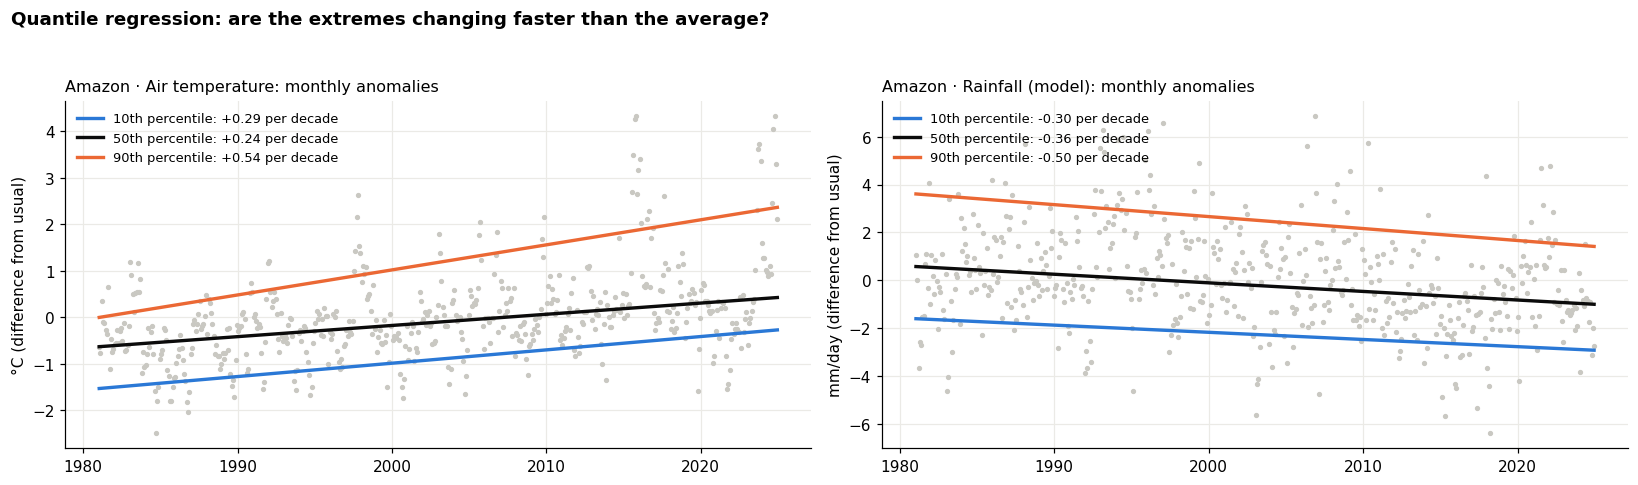

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
colours = {0.1: BLUE, 0.5: INK, 0.9: ORANGE}
for ax, (place, col) in zip(axes, [("amazon", "T2M"), ("amazon", "PRECTOTCORR")]):
    a = monthly_anomalies(place, col)
    x = (a.index.year + (a.index.month - 0.5) / 12).values
    X = sm.add_constant(x - x.mean())
    ax.scatter(x, a.values, s=6, color=GREY)
    for q in QUANTILES:
        res = sm.QuantReg(a.values, X).fit(q=q)
        ax.plot(x, X @ res.params, color=colours[q], lw=2.2,
                label=f"{int(q*100)}th percentile: {res.params[1]*10:+.2f} per decade")
    ax.set_title(f"{place.title()} · {VARIABLES[col][0]}: monthly anomalies")
    ax.set_ylabel(f"{VARIABLES[col][1]} (difference from usual)")
    ax.legend(fontsize=8.5, loc="upper left")
fig.suptitle("Quantile regression: are the extremes changing faster than the average?",
             x=0.01, ha="left", fontweight="bold", y=1.04)
fig.tight_layout()
plt.show()

## 6. Gaussian process regression: a smooth, non-linear trend (Multivariate notes §7.2)
A Gaussian process puts a probability distribution over smooth curves. Kernel: constant × RBF (the smooth trend) + white noise (year-to-year weather). The hyperparameters (how smooth, how noisy) are learned by maximising the marginal likelihood. The band shows the 95% credible interval for the underlying trend.

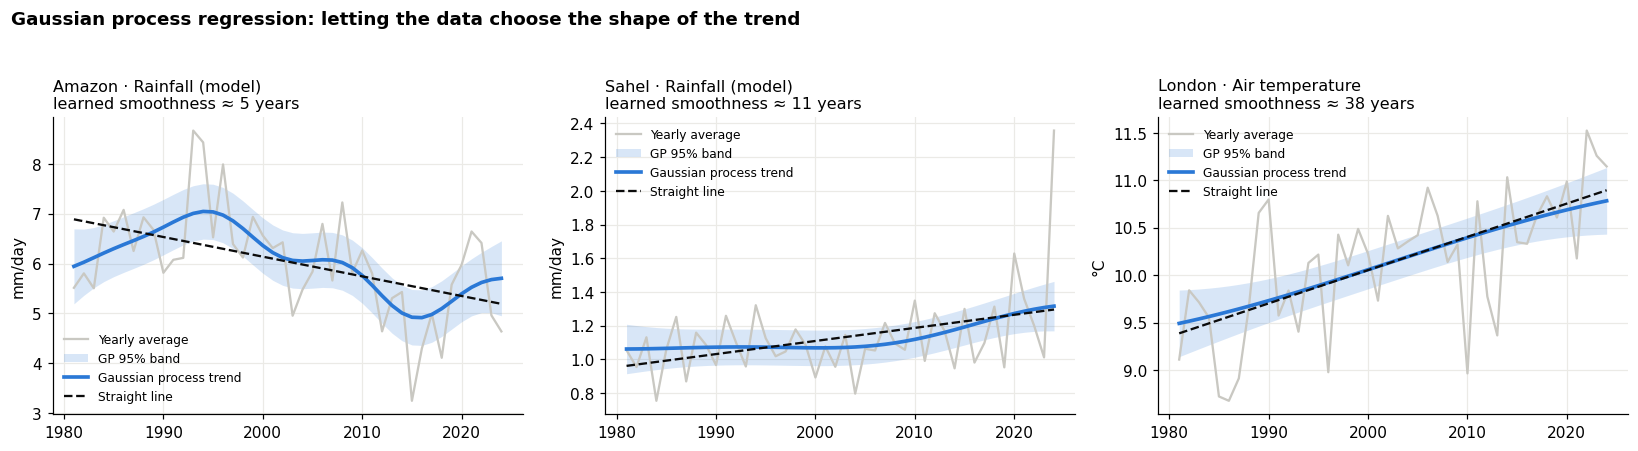

In [9]:
def gp_trend(t, y):
    x = (t - t.mean())[:, None]
    kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(15.0, (5.0, 200.0)) + WhiteKernel(1.0, (1e-4, 1e2))
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=5, random_state=0).fit(x, y)
    noise = gp.kernel_.k2.noise_level
    smooth = GaussianProcessRegressor(kernel=gp.kernel_.k1, alpha=noise, optimizer=None, normalize_y=True).fit(x, y)
    mean, sd = smooth.predict(x, return_std=True)
    return mean, sd, gp.kernel_

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for ax, (place, col) in zip(axes, [("amazon", "PRECTOTCORR"), ("sahel", "PRECTOTCORR"), ("london", "T2M")]):
    t, y = yearly(place, col)
    mean, sd, k = gp_trend(t, y)
    lin = np.polyval(np.polyfit(t, y, 1), t)
    ax.plot(t, y, color=GREY, lw=1.5, label="Yearly average")
    ax.fill_between(t, mean - 1.96 * sd, mean + 1.96 * sd, color=BLUE, alpha=0.18, lw=0, label="GP 95% band")
    ax.plot(t, mean, color=BLUE, lw=2.4, label="Gaussian process trend")
    ax.plot(t, lin, color=INK, lw=1.5, ls="--", label="Straight line")
    ax.set_title(f"{place.title()} · {VARIABLES[col][0]}\nlearned smoothness ≈ {k.k1.k2.length_scale:.0f} years")
    ax.set_ylabel(VARIABLES[col][1])
    ax.legend(fontsize=8, loc="best")
fig.suptitle("Gaussian process regression: letting the data choose the shape of the trend",
             x=0.01, ha="left", fontweight="bold", y=1.04)
fig.tight_layout()
plt.show()

## 7. EOF / PCA: the "Earth-system mode" of each place (Multivariate notes §3.5)
For each place, the 10 variables' yearly values (2000–2024) are standardised and decomposed with PCA (called **EOF analysis** in climate science). The first component is the dominant pattern of variables moving **together**, e.g. hot + dry + hazy years. A Mann-Kendall test on its score asks whether that whole coupled pattern is trending. (Exploratory: 25 years × 10 variables.)

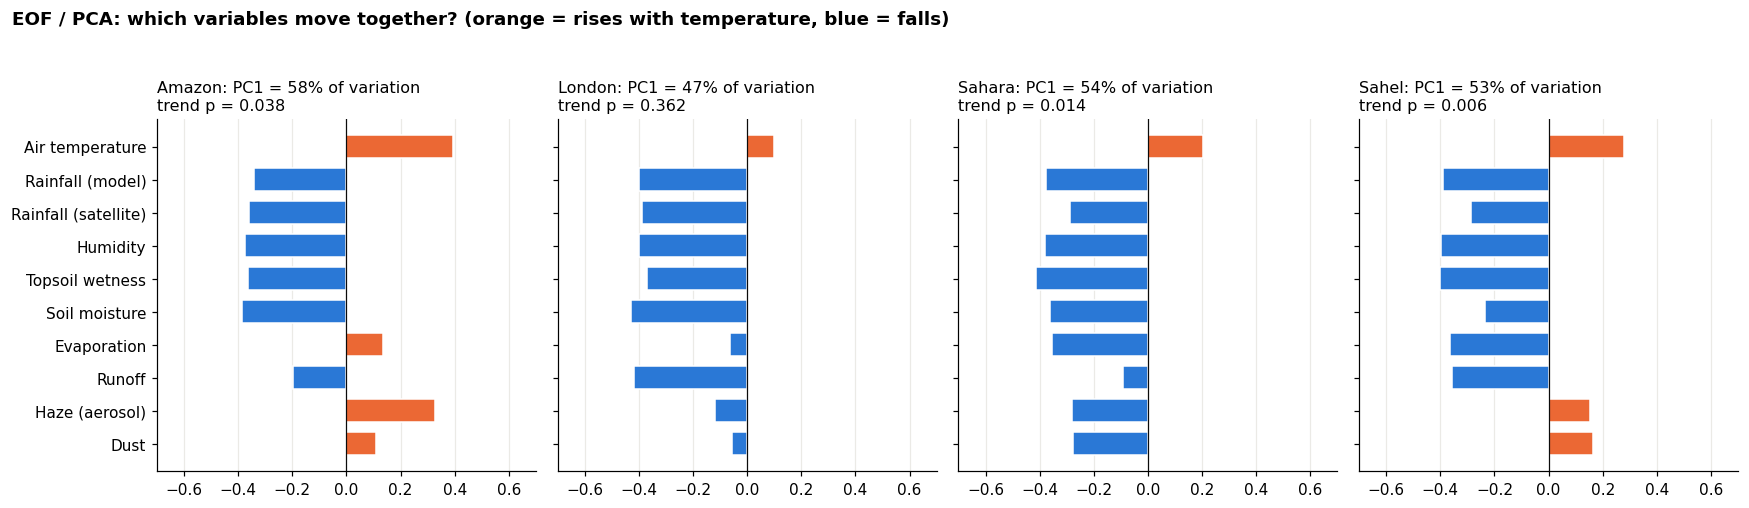

,Place,PC1 explains,PC2 explains,Strongest variables in PC1,PC1 trend (MK) p,PC1 trend
0,Amazon,0.579,0.173,"Air temperature (+0.39), Soil moisture (-0.39)...",0.038,increasing
1,London,0.467,0.187,"Soil moisture (-0.43), Runoff (-0.42), Humidit...",0.362,no trend
2,Sahara,0.540,0.170,"Topsoil wetness (-0.41), Humidity (-0.38), Rai...",0.014,increasing
3,Sahel,0.532,0.208,"Topsoil wetness (-0.40), Humidity (-0.40), Rai...",0.006,decreasing


In [10]:
cols = list(VARIABLES)
rows, loadings, scores = [], {}, {}
for place in PLACES:
    g = df[(df.place == place) & (df.year >= 2000)].groupby("year")[cols].mean()
    g = g.dropna(axis=1)
    Z = ((g - g.mean()) / g.std()).values
    U, S, Vt = np.linalg.svd(Z, full_matrices=False)
    explained = S ** 2 / np.sum(S ** 2)
    load = pd.Series(Vt[0], index=g.columns)
    if load.get("T2M", 1) < 0:                          # sign convention: warmer = positive
        load, U = -load, -U
    pc1 = U[:, 0] * S[0]
    loadings[place], scores[place] = load, pd.Series(pc1, index=g.index)
    trend = mk.original_test(pc1)
    top = load.abs().sort_values(ascending=False).index[:3]
    rows.append({"Place": place.title(), "PC1 explains": explained[0], "PC2 explains": explained[1],
                 "Strongest variables in PC1": ", ".join(f"{VARIABLES[c][0]} ({load[c]:+.2f})" for c in top),
                 "PC1 trend (MK) p": trend.p, "PC1 trend": trend.trend})
sec7 = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
names = [VARIABLES[c][0] for c in cols]
for ax, place in zip(axes, PLACES):
    load = loadings[place].reindex(cols)
    ax.barh(names, load.values, color=np.where(load.values > 0, ORANGE, BLUE), height=0.7,
            edgecolor="white", linewidth=1)
    ax.axvline(0, color=INK, lw=0.8)
    r = sec7[sec7.Place == place.title()].iloc[0]
    ax.set_title(f"{place.title()}: PC1 = {r['PC1 explains']:.0%} of variation\ntrend p = {r['PC1 trend (MK) p']:.3f}")
    ax.set_xlim(-0.7, 0.7)
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.suptitle("EOF / PCA: which variables move together? (orange = rises with temperature, blue = falls)",
             x=0.01, ha="left", fontweight="bold", y=1.04)
fig.tight_layout()
plt.show()
sec7.round(3)

## 8. Lagged cross-correlation: how long does the soil remember rain?
Correlation between this month's rainfall anomaly (GPM satellite) and soil-moisture anomaly (GLDAS) 0–6 months later. A slow decay = the land has a long memory, which links the water and land parts of the Earth system.

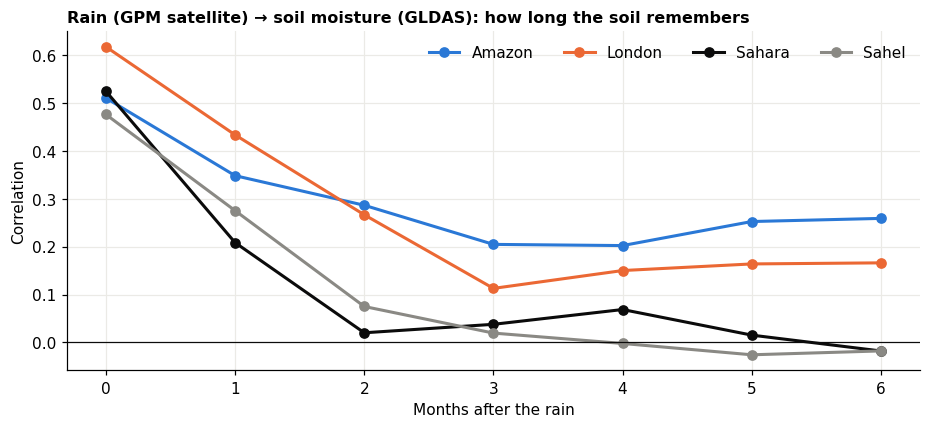

,Place,lag 0,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,Peak lag (months)
0,Amazon,0.511,0.348,0.287,0.205,0.202,0.253,0.259,0
1,London,0.618,0.434,0.267,0.113,0.150,0.164,0.166,0
2,Sahara,0.525,0.208,0.020,0.038,0.069,0.015,-0.018,0
3,Sahel,0.476,0.275,0.075,0.019,-0.002,-0.026,-0.018,0


In [11]:
lags = range(0, 7)
fig, ax = plt.subplots(figsize=(10, 4))
rows = []
for place, colour in zip(PLACES, [BLUE, ORANGE, INK, "#8a8984"]):
    r = monthly_anomalies(place, "gpm_rain")
    s = monthly_anomalies(place, "soil_moisture")
    both = pd.concat([r, s], axis=1, keys=["rain", "soil"]).dropna()
    cc = [both["rain"].corr(both["soil"].shift(-k)) for k in lags]
    ax.plot(list(lags), cc, marker="o", lw=2, color=colour, label=place.title())
    rows.append({"Place": place.title(), **{f"lag {k}": c for k, c in zip(lags, cc)},
                 "Peak lag (months)": int(np.nanargmax(cc))})
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel("Months after the rain")
ax.set_ylabel("Correlation")
ax.legend(ncol=4, loc="upper right")
ax.set_title("Rain (GPM satellite) → soil moisture (GLDAS): how long the soil remembers", fontweight="bold")
plt.show()
sec8 = pd.DataFrame(rows)
sec8.round(3)

## 9. Do two NASA sources agree? (model vs satellite rainfall)
- **Bland–Altman:** average difference (bias) and 95% limits of agreement between MERRA-2 and GPM monthly rainfall.
- **Trend of the difference:** test whether (MERRA-2 − GPM) has its own trend. If it does, the two sources disagree about the *trend*, so a trend seen in only one of them should not be trusted.

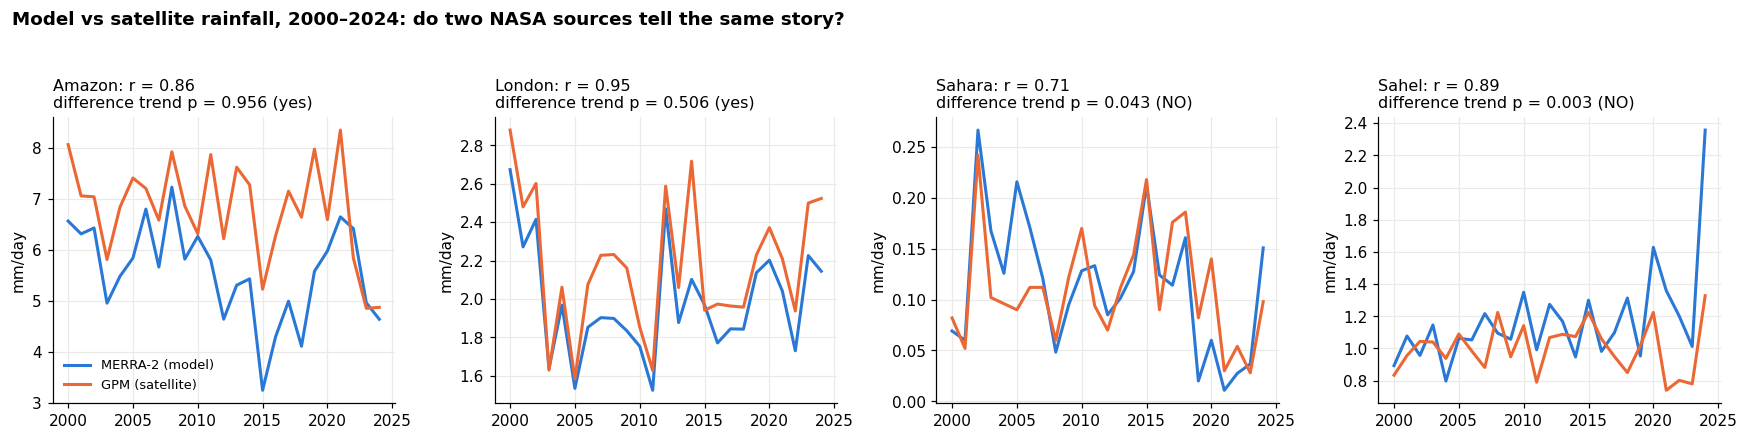

,Place,Monthly correlation,Bias (MERRA-2 − GPM),Limits of agreement low,Limits of agreement high,Trend of difference (per decade),Trend of difference p,Sources agree on trend?
0,Amazon,0.862,-1.218,-4.708,2.272,-0.014,0.956,yes
1,London,0.951,-0.190,-0.934,0.553,-0.026,0.506,yes
2,Sahara,0.705,0.003,-0.313,0.318,-0.025,0.043,NO
3,Sahel,0.886,0.169,-1.559,1.896,0.209,0.003,NO


In [12]:
rows = []
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, place in zip(axes, PLACES):
    g = df[(df.place == place)][["date", "year", "PRECTOTCORR", "gpm_rain"]].dropna()
    diff = g["PRECTOTCORR"] - g["gpm_rain"]
    bias, sd = diff.mean(), diff.std()
    yd = g.groupby("year")[["PRECTOTCORR", "gpm_rain"]].mean()
    d = (yd["PRECTOTCORR"] - yd["gpm_rain"]).values
    t = yd.index.values.astype(float)
    dfit = stats.linregress(t - t.mean(), d)
    rows.append({"Place": place.title(), "Monthly correlation": g["PRECTOTCORR"].corr(g["gpm_rain"]),
                 "Bias (MERRA-2 − GPM)": bias, "Limits of agreement low": bias - 1.96 * sd,
                 "Limits of agreement high": bias + 1.96 * sd,
                 "Trend of difference (per decade)": dfit.slope * 10, "Trend of difference p": dfit.pvalue,
                 "Sources agree on trend?": "yes" if dfit.pvalue >= 0.05 else "NO"})
    ax.plot(t, yd["PRECTOTCORR"], color=BLUE, lw=2, label="MERRA-2 (model)")
    ax.plot(t, yd["gpm_rain"], color=ORANGE, lw=2, label="GPM (satellite)")
    ax.set_title(f"{place.title()}: r = {rows[-1]['Monthly correlation']:.2f}\n"
                 f"difference trend p = {dfit.pvalue:.3f} ({rows[-1]['Sources agree on trend?']})")
    ax.set_ylabel("mm/day")
axes[0].legend(fontsize=8.5, loc="best")
fig.suptitle("Model vs satellite rainfall, 2000–2024: do two NASA sources tell the same story?",
             x=0.01, ha="left", fontweight="bold", y=1.04)
fig.tight_layout()
plt.show()
sec9 = pd.DataFrame(rows)
sec9.round(3)

## 10. Robust verdict: what survives every check?
A trend is called **robust** only if it is significant under the autocorrelation-aware tests (Hamed–Rao MK *and* GLS-AR(1)), the block-bootstrap interval excludes zero, and it survives the Benjamini–Hochberg false-discovery-rate correction across all 40 tests (Stat 2 §17.4).

In [13]:
def bh(p):
    """Benjamini–Hochberg q-values; missing p-values (e.g. a variable that never changes) stay missing."""
    p = np.asarray(p, dtype=float); out = np.full(len(p), np.nan)
    ok = ~np.isnan(p); pv = p[ok]; m = len(pv); o = np.argsort(pv)
    q = np.minimum.accumulate((pv[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    tmp = np.empty(m); tmp[o] = np.minimum(q, 1); out[ok] = tmp
    return out

v = sec1[["Place", "Variable", "Units", "OLS per decade"]].copy()
v["Sen per decade"] = sec2["Sen per decade"]
v["Hamed–Rao p"] = sec1["Hamed–Rao MK p"]
v["GLS-AR(1) p"] = sec1["GLS-AR(1) p"]
v["Block bootstrap excludes 0"] = (sec1["Block-bootstrap CI low"] > 0) | (sec1["Block-bootstrap CI high"] < 0)
v["q (FDR, Hamed–Rao)"] = bh(sec1["Hamed–Rao MK p"])
v["P(direction) Bayesian"] = sec4["P(direction is real)"]
v["Change point"] = np.where(sec3["Pettitt p"] < 0.05, sec3["Pettitt change year"].astype(str), "—")
v["Robust?"] = np.where((v["Hamed–Rao p"] < .05) & (v["GLS-AR(1) p"] < .05) & v["Block bootstrap excludes 0"]
                        & (v["q (FDR, Hamed–Rao)"] < .05), "ROBUST",
                        np.where((v["Hamed–Rao p"] < .05) | (v["GLS-AR(1) p"] < .05), "Likely", "Not shown"))
print(v["Robust?"].value_counts().to_dict())
v.round(4).style.map(lambda s: "background-color: #d4edda" if s == "ROBUST" else
                     "background-color: #fff3cd" if s == "Likely" else
                     "background-color: #f8d7da" if s == "Not shown" else "", subset=["Robust?"])

{'Not shown': 16, 'Likely': 16, 'ROBUST': 8}


,Place,Variable,Units,OLS per decade,Sen per decade,Hamed–Rao p,GLS-AR(1) p,Block bootstrap excludes 0,"q (FDR, Hamed–Rao)",P(direction) Bayesian,Change point,Robust?
0,Amazon,Air temperature,°C,0.325800,0.290000,0.000000,0.000400,True,0.000000,1.000000,2005,ROBUST
1,Amazon,Rainfall (model),mm/day,-0.394900,-0.381800,0.014000,0.008100,True,0.049800,0.999500,2003,ROBUST
2,Amazon,Rainfall (satellite),mm/day,-0.461900,-0.487500,0.129000,0.187700,False,0.201200,0.958100,—,Not shown
3,Amazon,Humidity,%,-0.831300,-0.637100,0.013200,0.037200,False,0.049800,0.995500,—,Likely
4,Amazon,Topsoil wetness,0-1,-0.015400,-0.015200,0.004600,0.076100,False,0.023000,0.986100,—,Likely
5,Amazon,Soil moisture,kg/m²,-0.650300,-0.474300,0.107100,0.218800,False,0.174000,0.980300,—,Not shown
6,Amazon,Evaporation,mm/day,0.077300,0.083200,0.539800,0.544500,False,0.638000,0.881900,—,Not shown
7,Amazon,Runoff,mm/day,0.028200,0.022600,0.726100,0.635000,False,0.786600,0.680400,—,Not shown
8,Amazon,Haze (aerosol),AOD,0.026100,0.024900,0.058500,0.042600,False,0.099200,0.992500,—,Likely
9,Amazon,Dust,AOD,0.002700,0.002600,0.019800,0.025200,False,0.055200,0.999400,2017,Likely
